In [6]:
import numpy as np
from numpy.polynomial import chebyshev as cheb
from scipy import optimize
import matplotlib.pyplot as plt
from tqdm import tqdm
import matplotlib as mpl
import matplotlib.cm as cm
from scipy.ndimage import zoom, gaussian_filter
import uuid
from numba import njit, prange
from numba_progress import ProgressBar
from scipy.stats import binned_statistic
import matplotlib.patches as mpatches
plt.rcParams['figure.dpi'] = 140

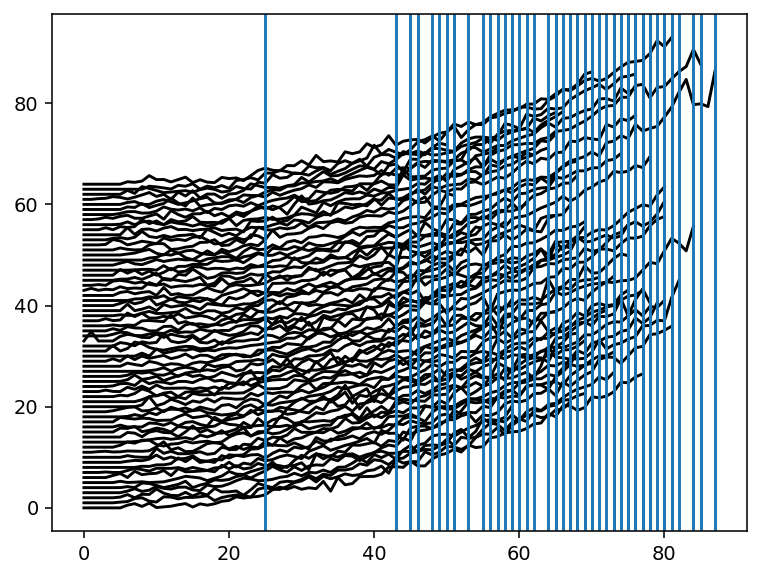

In [22]:
data = np.genfromtxt("stiff40_1.csv", delimiter=',', skip_header=1)
#data = np.genfromtxt("stiff40_ru0.15_xu0.2_FT_curve_KP_19022024.csv", delimiter=',', skip_header=1)
#data = np.genfromtxt("stiff20_ru0.15_xu0.2_FT_curve_KP_19022024.csv", delimiter=',', skip_header=1)

t = data[:, -1]
F = data[:, :-1].T
F[F<0] = 0
events = np.isnan(F).argmax(axis=1)
events[events==0] = t.shape[0]
events -= 1
for i, f in enumerate(F):
    plt.plot(f+1*i, 'k')

for e in events:
    plt.axvline(e)

In [23]:
t

array([ 0.        ,  0.1010101 ,  0.2020202 ,  0.3030303 ,  0.4040404 ,
        0.50505051,  0.60606061,  0.70707071,  0.80808081,  0.90909091,
        1.01010101,  1.11111111,  1.21212121,  1.31313131,  1.41414141,
        1.51515152,  1.61616162,  1.71717172,  1.81818182,  1.91919192,
        2.02020202,  2.12121212,  2.22222222,  2.32323232,  2.42424242,
        2.52525253,  2.62626263,  2.72727273,  2.82828283,  2.92929293,
        3.03030303,  3.13131313,  3.23232323,  3.33333333,  3.43434343,
        3.53535354,  3.63636364,  3.73737374,  3.83838384,  3.93939394,
        4.04040404,  4.14141414,  4.24242424,  4.34343434,  4.44444444,
        4.54545455,  4.64646465,  4.74747475,  4.84848485,  4.94949495,
        5.05050505,  5.15151515,  5.25252525,  5.35353535,  5.45454545,
        5.55555556,  5.65656566,  5.75757576,  5.85858586,  5.95959596,
        6.06060606,  6.16161616,  6.26262626,  6.36363636,  6.46464646,
        6.56565657,  6.66666667,  6.76767677,  6.86868687,  6.96

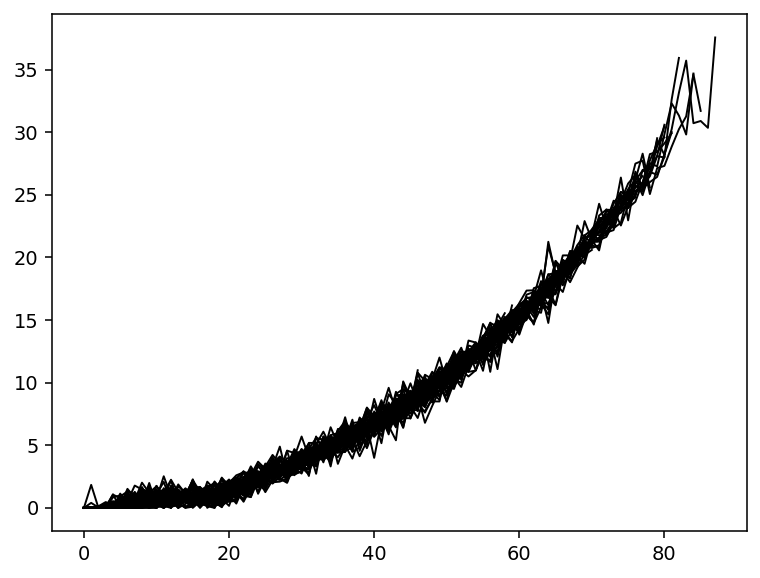

In [24]:
for i, f in enumerate(F):
    plt.plot(f, 'k', linewidth=1)

In [25]:
dt = np.diff(t).mean()
dt

0.10101010101010102

In [26]:
@njit(parallel=True, nogil=True)
def nb_likelihood(logprior, ruxu, T, event, dt, pbar=None, kl_per_T=False, kT=4.112):

    n_samples = logprior.shape[0]
    n_trajectories = event.shape[0]
    logposterior = logprior.copy()

    if kl_per_T:
        klT = np.zeros(n_trajectories)

    for s in prange(n_samples):
        ru = ruxu[s, 0]
        xu = ruxu[s, 1]
        for t in range(n_trajectories):
            for i in range(int(event[t])):
                p = 1 - dt * ru * np.exp(T[i, t] * xu /kT)
                
                if p > 1:
                    p = 1
                if p < 0:
                    p = 0
                    
                if i + 1 == event[t]: # in case of unbinding
                    p = 1 - p

                logp = np.log(p + 1e-10)
                logposterior[s] += logp
                if kl_per_T:
                    klT[t] += logp
        #pbar.update(1)

    return logposterior, klT

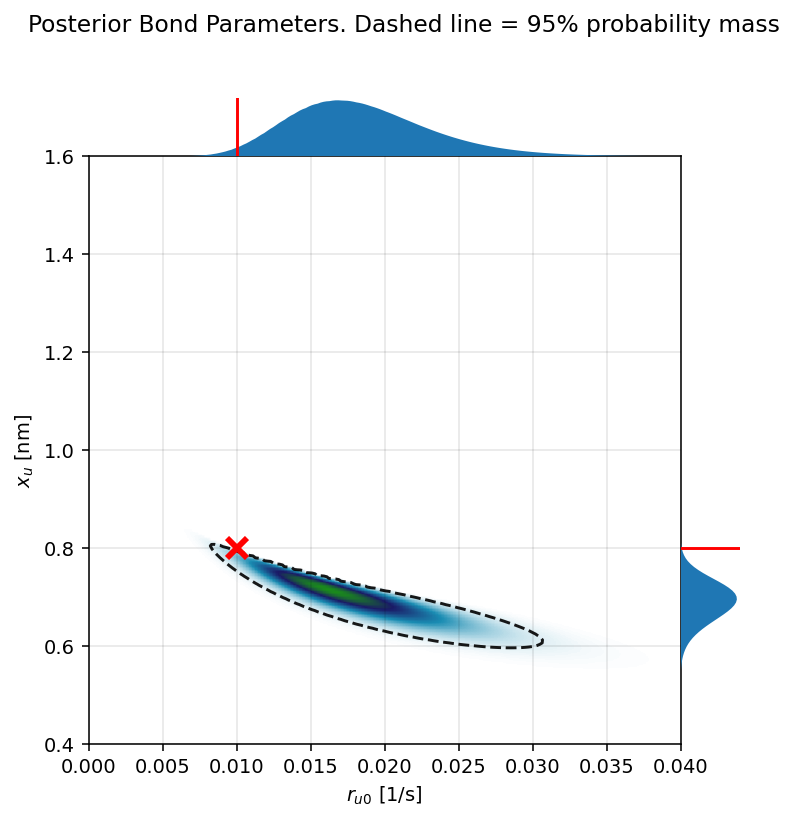

In [27]:
ru_GT = 0.01
xu_GT = 0.8
resolution = 200


ru_min = 0 * xu_GT
ru_max = 4 * ru_GT
xu_min = 0.5 * xu_GT
xu_max = 2 * xu_GT


ru = np.linspace(ru_min, ru_max, resolution)
xu = np.linspace(xu_min, xu_max, resolution)

ruxu = np.stack(np.meshgrid(ru, xu)).reshape((-1, resolution**2)).T

logprior = np.zeros(resolution**2)
logpost, klT = nb_likelihood(logprior, ruxu, F.T, events, dt=dt)

logpost_ = logpost.copy().reshape((resolution, -1))
logpost_ -= np.nanmax(logpost_)
draw = np.exp(logpost_)

draw_flat = np.sort(draw.flatten())
CDF = np.cumsum(draw_flat)
CDF = CDF / CDF[-1]
perc = 95
idx = np.argmax(CDF > (100 - perc)/100)

fig = plt.figure(figsize=(6,6))
gs = fig.add_gridspec(2, 2, width_ratios=(10,1), height_ratios=(1,10), hspace=0.00, wspace=0.00)

ax = fig.add_subplot(gs[1, 0])
ax.imshow(draw, origin='lower', cmap='ocean_r',
           extent=(ru_min, ru_max, xu_min, xu_max),
           aspect='auto',
           alpha=0.9)
ax.contour(draw, origin='lower', colors='k',
            linestyles='--',
            extent=(ru_min, ru_max, xu_min, xu_max),
            levels=[draw_flat[idx]],
            alpha=0.9)
plt.xlabel("$r_{u0}$ [1/s]")
plt.ylabel("$x_u$ [nm]")
plt.plot([ru_GT],[xu_GT], 'xr', ms=10, mew=3)
plt.gca().grid(c='k',alpha=0.1)
axx = fig.add_subplot(gs[0,0])
axx.fill_between(np.linspace(ru_min, ru_max, resolution), np.sum(draw, axis=0))
axx.axvline(ru_GT, c='r', linestyle='-')
#axx.set_yticklabels([])
ax.set_xlim((ru_min, ru_max))
ax.set_ylim((xu_min, xu_max))
axx.set_xlim((ru_min, ru_max))
axx.set_ylim((0, None))
axx.set_xticklabels([])
axx.set_xticks([])
axx.set_yticklabels([])
axx.set_yticks([])
axx.axis('off')
axy = fig.add_subplot(gs[1,1])
axy.fill_between(np.sum(draw, axis=1), np.linspace(xu_min, xu_max, resolution))
axy.axhline(xu_GT, c='r', linestyle='-')
axy.set_xticklabels([])
axy.set_xticks([])
axy.set_yticklabels([])
axy.set_yticks([])
axy.set_ylim((xu_min, xu_max))
axy.set_xlim((0, None))
axy.axis('off')


fig.suptitle("Posterior Bond Parameters. Dashed line = 95% probability mass")
plt.savefig("posterior.png", dpi=300)
